## ![](https://ga-dash.s3.amazonaws.com/production/assets/logo-9f88ae6c9c3871690e33280fcf557f33.png) Convolutional Neural Networks



**By the end of the lesson, you should be able to:**
- Identify use cases for convolutional neural networks and when they are superior to other neural networks.
- Describe convolutional and pooling layers.
- Define padding and filters.
- Fit CNNs in Keras.

Convolutional neural networks are generally used when we are dealing with image data.

Their main advantage over densely connected neural networks is **efficiency**.

In order to illustrate this, let's build out a feedforward neural network and tackle the [MNIST Handwritten Digits Dataset](https://www.tensorflow.org/datasets/catalog/mnist).

In [55]:
# Import libraries and modules
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

# For reproducibility
np.random.seed(42)

from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, ________, ________, Input
from keras.callbacks import EarlyStopping

from sklearn.metrics import accuracy_score, recall_score
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

from keras.datasets import mnist

from keras.utils import set_random_seed
SEED = 42

In [56]:
# Load pre-shuffled MNIST data into train and test sets
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [57]:
# Check one value of X_train.
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [58]:
# Check max pixel value
X_train[0].max()

255

In [59]:
# Check shape of an image.
X_train[0].shape

(28, 28)

In [60]:
# unique classes in y_train
np.unique(y_train).size

10

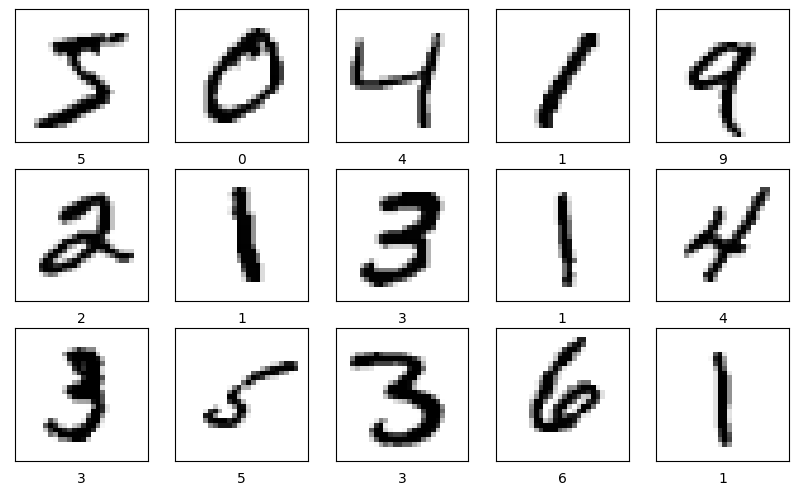

In [61]:
# plot some of the digits

class_names=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

fig_fashion = plt.figure(figsize=(10, 10))

for i in range(15):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i], cmap="binary")
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    # y_train[i] is the number; class_names[y_train[i]] is the word
    plt.xlabel( class_names[y_train[i]] )
plt.show()

##### We want to scale our data to be betwen 0 and 1.

When working with image data, we commonly scale it to be between 0 and 1. This is a common choice if we are pulling images from various sources that are on a different scale, and can improve speed by keeping values close to 0. Depending on the type of computation you want to do, having pixel values represented with `255` might not be ideal.

In [62]:
# Make sure each value is a float. (Otherwise, we get an error.)



# scale
# The current range of X_train and X_test is 0 to 255.
# This scales each value to be between 0 and 1.

X_train = X_train/255
X_test = X_test/255



<img src="./images/picture.png" alt="drawing" width="400"/>

[Image by 3Blue1Brown](https://www.youtube.com/channel/UCYO_jab_esuFRV4b17AJtAw)

In [63]:
# Check shape of full training data.
X_train.shape

(60000, 28, 28)

In [64]:
# Check shape of full testing data.
X_test.shape

(10000, 28, 28)

##### We want to reshape each image to be 28 x 28 x 1.

This allows our neural network to know that there's only one value (how dark the pixel is) instead of multiple values per pixel. For example, a color image stored in RGB (red/green/blue) might have shape 28 x 28 x 3, where one value is corresponds to how red the pixel is, one value corresponds to how blue the pixel is, and one value corresponds to how green the pixel is.

In [65]:
# Reshape each image to be 28 x 28 x 1.
# The 1 corresponds to the one black/white value.
# If we had a color image, we would likely use 3 for RGB.

X_train = ??
X_test = ??

# -1: Automatically determines the number of images.
# 28, 28: Height and width of each image.
# 1: One channel (grayscale). RGB images would have 3 channels.

In [66]:
# Recheck X_Train shape


# 60000 → batch size 
# 28 → Image height (28 pixels)
# 28 → Image width (28 pixels)
# 1 → Each pixel has 1 value

# If using colored image
# 3 → Each pixel has 3 values (Red, Green, Blue)

(60000, 28, 28, 1)

Now let's check out `y_train`.

array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4], dtype=uint8)

<details><summary>What change do I need to make to y_train? Why?</summary>

- Right now, the values of `y_train` will be interpreted as a number. Our neural network would try to predict values that are numerically close to the true value. (i.e. If $Y = 5$, then $\hat{Y} = 4$ would be way better than $\hat{Y} = 1$. **This isn't actually what we want!**

* **Option 1 (Explicit Conversion)**:
    * Use `to_categorical` in Keras/TensorFlow or `OneHotEncoder` in Scikit-Learn before training.
* **Option 2 (Implicit Loss Function)**:
    * If you prefer to keep y_train as integers, you must change your loss function to `Sparse Categorical Crossentropy` (in Keras/PyTorch). This tells the network internally to treat the integers as distinct categories rather than continuous numbers.
</details>

## The not efficient way to understand images

In order to "align" our neurons in a vertical array, we add a "Flatten" layer. This was be required before adding subsequent Dense layers.

<img src="./images/flattening_image.png" alt="drawing" width="500"/>

[Image source.](https://sds-platform-private.s3-us-east-2.amazonaws.com/uploads/73_blog_image_1.png)

<img src="./images/picture.png" alt="drawing" width="400"/>

<img src="./images/network.png" alt="drawing" width="400"/>

[Images by 3Blue1Brown](https://www.youtube.com/channel/UCYO_jab_esuFRV4b17AJtAw)

<details><summary>If my model were to be underfit, what might I do?</summary>

- I could try decreasing the batch size.
- I could try increasing the number of epochs.
- I could try increasing the number of layers.
- I could try increasing the number of nodes in each layer.
</details>

<details><summary>What are some consequences of fitting a model with too many parameters?</summary>

- Easy to overfit our model.
- Learning is quite slow.
- We need more data in order to meaningfully learn and fit a model!
</details>

## Convolutional Neural Networks
Convolutional neural networks are a great way to get around this issue of too many parameters. CNNs do some complicated math up front to "compress our images," allowing us to learn far fewer parameters in later layers.

A CNN will generally consist of three types of layers:
- Convolutional Layer
- Pooling Layer
- Densely Connected Layer

<img src="./images/cnn.jpeg" alt="drawing" width="600"/>

[Image source.](https://towardsdatascience.com/a-comprehensive-guide-to-convolutional-neural-networks-the-eli5-way-3bd2b1164a53)

This isn't overly helpful if we're trying to learn what CNNs are/do.

### Convolution Layer

The convolution layer is where we pass a filter over an image and do some calculation at each step. Specifically, we take pixels that are close to one another, then summarize them with one number. The goal of the convolution layer is to identify important features in our images, like edges.

<img src="./images/convolution.gif" alt="drawing" width="550"/>

[Image source.](https://ujjwalkarn.me/2016/08/11/intuitive-explanation-convnets/)

Our hyperparameters here are:
- the number of filters to use. This is given by `filters = 6`.
- the dimensions of the filter. This is given by `kernel_size = 3` (a 3x3 filter).

**How many filters should we use?** Well, this is a hyperparameter. There's not one great answer, but the idea is that each filter can detect one type of feature in an image (like vertical edges). This may depend on the complexity of your images (simpler images require fewer filters) and usually requires trial and error to identify an adequate value of `filters`. [Source](https://stats.stackexchange.com/questions/196646/what-is-the-significance-of-the-number-of-convolution-filters-in-a-convolutional)

#### Padding

When we pass a filter over an image, each of the "inside" pixels is counted pretty frequently and thus gets "represented" more in the final model output.

<details><summary>How many times does each corner get included in the "output?"</summary>

- Right now, each corner gets included only once.
</details>

We can use **padding** to add a border of white cells around the edge of the image. This will allow pixels on the edge/in the corner to be included more frequently. (This might be good when doing computer vision for self-driving vehicles!)

<details><summary>In this MNIST digits case, do you think padding is a good idea or a bad idea?</summary>

- Padding is probably a bad idea here. We're increasing the number of parameters we need to learn, but it's unlikely that we're getting important data from the corners/edges of the image. 
</details>

### Pooling Layer

Remember that CNNs learn far fewer parameters than a regular feed-forward neural network. Most of the "parameter reduction" comes from the pooling layer.

<img src="./images/maxpool.png" alt="drawing" width="400"/>

[Image source.](https://ujjwalkarn.me/2016/08/11/intuitive-explanation-convnets/)


In Max Pooling, we pass a filter over an image. At each step, we take the maximum value and record it as part of the output.
- Average Pooling exists, but is far less frequently used. [Andrew Ng](https://www.deeplearning.ai/deep-learning-specialization/) recommends using Max Pooling.
- When pooling, we generally partition the result from the previous layer. That is, the filter does not usually overlap like it does in the convolutional layer.

Our hyperparameters here are the **dimensions of the filter we use when pooling**. This is given by `pool_size = (2, 2)` in our example.

##### Why use max pooling?
1. Reduces the data dimensionality.
2. Protects against overfitting by creating a more abstract representation.
3. Provides some invariance by ignoring insignificant local changes in the image.

### Flattening Phase
- Once the image processing and edge detection is done, we need to make Flatten to make the data ready for the Dense NN

<img src="./images/flattening_image.png" alt="drawing" width="500"/>

[Image source.](https://sds-platform-private.s3-us-east-2.amazonaws.com/uploads/73_blog_image_1.png)

## CNN Explainer

- Explore the following site to see how CNN works
[CNN Explainer](https://poloclub.github.io/cnn-explainer/)

### Final Model
- Let's put everything together for our final model


In [69]:
# Instantiate a CNN.
cnn_model = ??

# Define the input shape.
??

# Add a convolutional layer.
??
# padding='valid' : no-padding, the output is smaller than the input
# padding='same' : padded with enough empty pixels to get an output of the *same* size as the input


# Add a pooling layer.
??
# pool_size=(2, 2): takes the maximum value from each 2x2 region, halving height and width.


# Add another convolutional layer.
??

# Add another pooling layer.
??

# We have to remember to flatten to go from the "box" to the vertical line of nodes!
??

# Add a densely-connected layer with 64 neurons.
??

# Let's try to avoid overfitting!
??

# Add a densely-connected layer with 32 neurons.
??

# Let's try to avoid overfitting!
??

# Add a final layer with 10 neurons.
??

# Compile model
cnn_model.compile(
    optimizer=________,
    loss=________,
    metrics=[________]
)

# Early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Fit model on training data
history = cnn_model.fit(
    X_train,
    y_train,
    batch_size=________,
    ________=________,
    epochs=________,
    callbacks=[early_stopping]
)

Epoch 1/3
375/375 [==============================] - 8s 21ms/step - loss: 0.5088 - accuracy: 0.8419 - val_loss: 0.0860 - val_accuracy: 0.9753
Epoch 2/3
375/375 [==============================] - 8s 21ms/step - loss: 0.1610 - accuracy: 0.9539 - val_loss: 0.0613 - val_accuracy: 0.9818
Epoch 3/3
375/375 [==============================] - 8s 22ms/step - loss: 0.1123 - accuracy: 0.9686 - val_loss: 0.0598 - val_accuracy: 0.9842


In [70]:
# Evaluation function
def eval_results (m, h):
    history_df = pd.DataFrame(h.history)
    history_df[['loss','val_loss']].plot();
    history_df[['accuracy','val_accuracy']].plot();
    y_pred = m.predict(X_test)
    y_pred_label= y_pred.argmax(axis=1)
    print( classification_report(y_test,y_pred_label) )
    ConfusionMatrixDisplay.from_predictions(y_test,
                                        y_pred_label,
                                        display_labels=class_names,
                                        xticks_rotation=90,    
                                        cmap="Blues");


313/313 [==============================] - 1s 3ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.98      1.00      0.99      1135
           2       0.98      0.99      0.99      1032
           3       1.00      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.98      0.99       892
           6       0.98      0.99      0.99       958
           7       0.97      0.99      0.98      1028
           8       0.99      0.98      0.98       974
           9       0.99      0.97      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



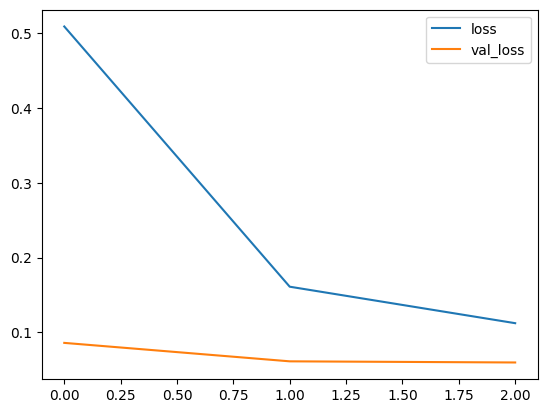

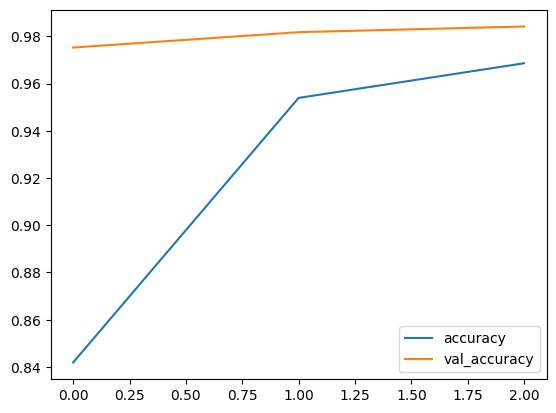

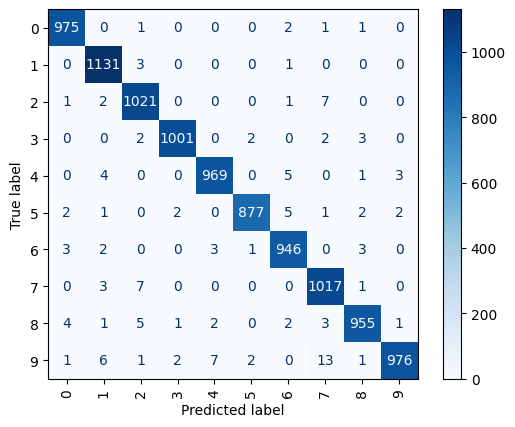

In [71]:
# Evaluate the model
??

In [30]:
# Model Summary
??

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 28, 28, 32)        832       
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 14, 14, 32)       0         
 2D)                                                             
                                                                 
 conv2d_3 (Conv2D)           (None, 14, 14, 64)        18496     
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 7, 7, 64)         0         
 2D)                                                             
                                                                 
 flatten_1 (Flatten)         (None, 3136)              0         
                                                                 
 dense_2 (Dense)             (None, 64)               

## Conclusion

Convolutional neural networks are uniquely suited to tackle image data.
- Dealing with images usually presents high-dimensional challenges. (A 28x28 image is a pretty low-resolution image.)

<details><summary>Why are convolutional neural networks better equipped to handle image data than non-CNNs?
</summary>

- CNNs are naturally set up to consider interactions among "close pixels" only and can drastically cuts down the number of parameters needed to learn. (Or get better performance for a given number of parameters!)
</details>

<details><summary>Can you think of other situations (i.e. not images) in which we might apply a convolutional neural network?</summary>

- **Videos**. A video is really just a sequence of pictures, so we might use a 3D convolutional neural network. (Length of the picture, width of the picture, and depth of the picture is time.)
- **Time series data**. Rather than passing a filter over neighboring pixels in pictures, what if we passed a filter over neighboring time periods in time series data?
- **Natural language data**. Rather than passing a filter over neighboring pixels in pictures, what if we passed a filter over neighboring words or tokens in natural language data?
- Convolutional neural networks exploit the inherent structure in data we pass in.
</details>

### 📊 Appendix: Common Convolutional Neural Network Filters

The table below summarizes the primary filter types that develop inside a Convolutional Neural Network. It breaks down their mathematical weight structures, their physical actions, and how they contribute to the network’s ultimate decision-making process.

| Filter Category | Typical 3x3 Weight Matrix Layout | Mathematical Action | Physical Effect on Image Data | Core Diagnostic Purpose |
| :--- | :--- | :--- | :--- | :--- |
| **Vertical Edge Detector** | $\begin{bmatrix} +1 & 0 & -1 \\ +1 & 0 & -1 \\ +1 & 0 & -1 \end{bmatrix}$ | Subtracts the average brightness of the right side from the left side. | Highlights vertical boundaries, borders, and doorframes. | Locates structural pillars, columns, and vertical geometry. |
| **Horizontal Edge Detector** | $\begin{bmatrix} +1 & +1 & +1 \\ 0 & 0 & 0 \\ -1 & -1 & -1 \end{bmatrix}$ | Subtracts the average brightness of the bottom row from the top row. | Highlights horizontal horizons, shelf lines, and flat borders. | Locates tables, roads, ceilings, and flat boundaries. |
| **Diagonal Edge Detector** | $\begin{bmatrix} 0 & +1 & +2 \\ -1 & 0 & +1 \\ -2 & -1 & 0 \end{bmatrix}$ | Subtracts the top-left section of the window from the bottom-right section. | Highlights 45-degree and 135-degree structural shifts. | Traces angled elements like roofs, triangle slopes, and handwritten slashes (e.g., in "7"). |
| **Laplacian Filter** | $\begin{bmatrix} -1 & -1 & -1 \\ -1 & +8 & -1 \\ -1 & -1 & -1 \end{bmatrix}$ | Compares a single central pixel against the collective brightness of all 8 surrounding neighbors. | Completely cancels out flat space. Ignites into a massive spike only at isolated single points. | Detects tiny dots, specs, intersections, cross-hatches, and sharp corner tips. |
| **Gaussian Blur (Smoothing)** | $\begin{bmatrix} 0.06 & 0.12 & 0.06 \\ 0.12 & 0.25 & 0.12 \\ 0.06 & 0.12 & 0.06 \end{bmatrix}$ | Calculates a weighted average of pixels, favoring the absolute center. Contains zero negative coefficients. | Blends neighboring pixels together, softening harsh definitions. | Eliminates grainy background noise and camera static before deep processing. |
| **Sharpening Filter** | $\begin{bmatrix} 0 & -1 & 0 \\ -1 & +5 & -1 \\ 0 & -1 & 0 \end{bmatrix}$ | Exaggerates the difference between a pixel and its immediate cardinal neighbors. | Enhances contrast lines, making textures and fine details more distinct. | Amplifies subtle pattern transitions so downstream filters can catch them easier. |
| **Identity Filter** | $\begin{bmatrix} 0 & 0 & 0 \\ 0 & +1 & 0 \\ 0 & 0 & 0 \end{bmatrix}$ | Multiplies the central pixel by 1 and completely wipes out all peripheral context. | Passes the input pixel stream through with absolutely zero transformation. | Retains a pure, untouched copy of the original data channel for deep layers. |
| **Semantic Object Detectors** | *Highly abstract combination arrays found deep in the network.* | Synthesizes the low-level edge maps generated by previous layers. | Triggers high-amplitude matrices when complex compound geometries align. | Identifies complex visual features such as car wheels, text characters, or eyes. |

---


###  Appendix: Useful Links

- [Convolution Visualizer](https://ezyang.github.io/convolution-visualizer/)
- [Kernel (image processing)](https://en.wikipedia.org/wiki/Kernel_(image_processing))
- [An Intuitive Explanation of Convolutional Neural Networks](https://ujjwalkarn.me/2016/08/11/intuitive-explanation-convnets/)
- [CNN Explainer](https://poloclub.github.io/cnn-explainer/)
- [Convolution layers](https://keras.io/api/layers/convolution_layers/)
- [Pooling layers](https://keras.io/api/layers/pooling_layers/)
---